# Population dynamics

## Getting the data

National Records of Scotland hosts a [time series of births and deaths in Scotland](https://www.nrscotland.gov.uk/publications/births-time-series-data/). You can download the data as an [excel spreadsheet](https://www.nrscotland.gov.uk/media/uwbfoukw/births-time-series-25.xlsx). The first thing that we need to do is to copy a local version of the data:

In [3]:
# Data available from https://www.nrscotland.gov.uk/media/uwbfoukw/births-time-series-25.xlsx
import os                                     # For operating system-related routines
from shutil import copyfileobj                # High-level file operations
from urllib.request import Request, urlopen   # Dealing with web stuff
import ssl,certifi

# The data directory
datadir = "./data"

# The output file
outfile = "births-time-series-25.xlsx"

# From where to download the data
url = "https://www.nrscotland.gov.uk/media/uwbfoukw/births-time-series-25.xlsx"

#context for url fetch (fixing ssl cert error that may occur)
context = ssl.create_default_context(cafile=certifi.where())

# Create the data directory if it does not exists
if not os.path.exists(datadir):
    os.makedirs(datadir)

# Where to store the file
file = os.path.join(datadir,outfile)

# Add a User-Agent header to mimic a standard browser
# The National Records of Scotland blocks Python's default 
# urllib User-Agent header (Python-urllib/3.x) to prevent 
# automated scraping.
req = Request(url, headers={'User-Agent': 'Mozilla/5.0'})

# Check if we need to download the file.
if os.path.isfile(file):
    print("Already have a local copy of the data.")
else:
    print("Downloading the data.")
    with urlopen(req,context=context) as in_stream, open(file, 'wb') as out_file:
        copyfileobj(in_stream, out_file)


## Inspecting the data

Open the Excel file to the contents you want.
Read a local copy of the Excel file and examine the sheets in it

In [17]:
import pandas as pd # Module to deal with data

# You can list the Excel sheet names using:
# 
# print(pd.ExcelFile(file).sheet_names)
#
# but the names may not be meaningful.

# We are interested in: Table BT.01: Number of Births by sex, Scotland, 1855 to 2025
sheet = "Table_BT.01"

# Read the file into a data frame.
# This only reads the first sheet by default, so we need to specify another sheet.
# We also want to skip the first three rows as they do not contain any useful 
# information.
df = pd.read_excel(file, sheet_name = sheet, skiprows=3)

# Look at the top entries
df.head()


,Year,Persons,Females,Males
0,1855,93349,45545,47804
1,1856,101821,49582,52239
2,1857,103415,50257,53158
3,1858,104018,50324,53694
4,1859,106543,51915,54628


## Plot the data

We use [matplotlib](https://matplotlib.org/) to plot the data. We want to have a quick look at the data. Plot the number of girls born against the number of boys.

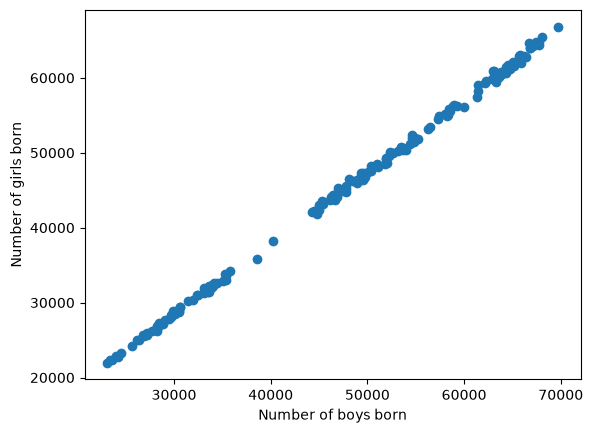

In [20]:
import matplotlib.pyplot as plt # Do plots

# Extract data to plot
x = df["Males"]
y = df["Females"]

# A scatter plot
fig, ax = plt.subplots()

ax.scatter(x, y)

plt.xlabel("Number of boys born")
plt.ylabel("Number of girls born")
plt.show()

The plot gives a straight line which seems to indicate that roughly the same number of girls and boys are born.

Let's look at the data more closely.

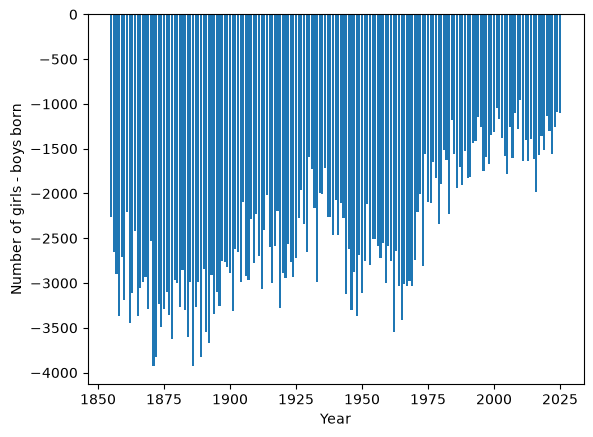

In [21]:
x = df["Year"]
y = df["Females"] - df["Males"]

# A scatter plot
fig, ax = plt.subplots()

ax.bar(x, y)

plt.xlabel("Year")
plt.ylabel("Number of girls - boys born")
plt.show()

More boys are born for every year! Difficult to tell proportions. Let's convert these to percentages.

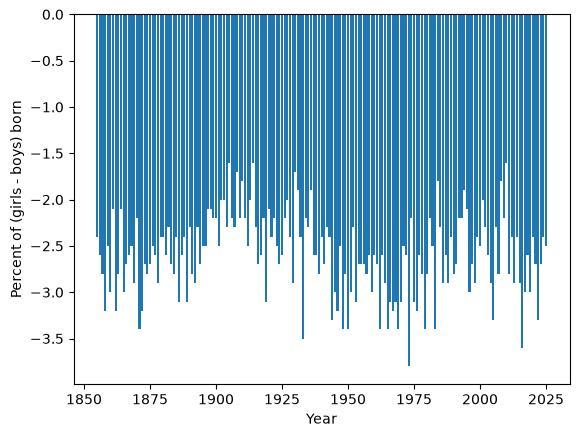

In [24]:

x = df["Year"]
# Convert the y-axis into a percentage
y = round((df["Females"] - df["Males"])/df["Persons"],3)*100

# A scatter plot
fig, ax = plt.subplots()

ax.bar(x, y)

plt.xlabel("Year")
plt.ylabel("Percent of (girls - boys) born")
plt.show()

Between 2-4% more boys than girls are born every year.